# Strategy backtest

In [1]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import logsumexp

pd.set_option("display.max_columns", None)

## Load data

In [2]:
train_df = pd.read_csv("train_df.csv", index_col=0)
test_df = pd.read_csv("test_df.csv", index_col=0)
market = pd.read_csv("nifty_index.csv")
test_regimes = pd.read_csv("causal_test_regimes.csv", index_col="market_row")
model = joblib.load("hmm_model.joblib")

features = [
    "daily_returns",
    "sign_persistence",
    "rolling_volatility",
    "trend",
]

train_df = train_df[features].astype(float)
test_df = test_df[features].astype(float)

market["Date"] = pd.to_datetime(market["Date"])
market["Close"] = pd.to_numeric(market["Close"], errors="coerce")
market["daily_returns"] = market["Close"].pct_change()

if train_df.empty or test_df.empty:
    raise ValueError("Train or test data is empty.")

if train_df.isna().any().any() or test_df.isna().any().any():
    raise ValueError("Feature data contains missing values.")

if train_df.index.max() >= test_df.index.min():
    raise ValueError("Train and test rows overlap.")

if test_regimes.index.min() < test_df.index.min():
    raise ValueError("Test regime rows do not match the test period.")

if not test_regimes.index.equals(test_df.index[:-1]):
    expected_rows = test_df.index[:-1]
    if not np.array_equal(test_regimes.index.to_numpy(), expected_rows.to_numpy()):
        raise ValueError("Regime file rows do not line up with test features.")

print("Train rows:", len(train_df))
print("Test rows:", len(test_df))
print("Test return rows:", len(test_regimes))

Train rows: 3708
Test rows: 927
Test return rows: 926


## Get training states

In [3]:
def filter_states(hmm_model, X, previous_probs=None):
    X = np.asarray(X, dtype=float)
    log_emissions = hmm_model._compute_log_likelihood(X)
    log_transition = np.log(np.clip(hmm_model.transmat_, 1e-300, 1.0))
    probs = np.zeros((len(X), hmm_model.n_components))

    if previous_probs is None:
        previous = hmm_model.startprob_.copy()
        first_row = True
    else:
        previous = np.asarray(previous_probs, dtype=float)
        previous = previous / previous.sum()
        first_row = False

    for i, emission in enumerate(log_emissions):
        if i == 0 and first_row:
            log_prior = np.log(np.clip(previous, 1e-300, 1.0))
        else:
            log_prior = logsumexp(
                np.log(np.clip(previous, 1e-300, 1.0))[:, None]
                + log_transition,
                axis=0,
            )

        log_probs = log_prior + emission
        log_probs -= logsumexp(log_probs)
        current = np.exp(log_probs)
        probs[i] = current
        previous = current

    return probs


train_probs = filter_states(model, train_df.to_numpy())
train_states = train_probs.argmax(axis=1)

train_rows = train_df.index.to_numpy(dtype=int)
market_by_row = market.reset_index(drop=True)
next_returns = market_by_row["daily_returns"].shift(-1)

train_map = pd.DataFrame({
    "market_row": train_rows,
    "state": train_states,
    "next_day_return": next_returns.iloc[train_rows].to_numpy(),
})
train_map = train_map.dropna(subset=["next_day_return"])

state_stats = train_map.groupby("state")["next_day_return"].agg(
    count="count",
    mean_return="mean",
    volatility="std",
)
state_stats["exposure"] = (state_stats["mean_return"] > 0).astype(float)

print("Training results by state:")
display(state_stats.round(5))

Training results by state:


,count,mean_return,volatility,exposure
state,,,,
0,1003,0.00015,0.01115,1.0
1,1004,0.00056,0.00696,1.0
2,568,0.00080,0.01910,1.0
3,879,0.00020,0.00996,1.0
4,254,0.00060,0.03030,1.0


## Make test signals

In [4]:
test = test_regimes.copy()
test.index = test.index.astype(int)
test = test.sort_index()

test["date"] = pd.to_datetime(test["date"])
test["next_day_return"] = pd.to_numeric(test["next_day_return"], errors="coerce")
test = test.dropna(subset=["next_day_return"])

# The state-to-exposure rule is learned from training data only.
exposure_map = state_stats["exposure"].to_dict()
test["hmm_exposure"] = test["state"].map(exposure_map).fillna(0.0)

# Simple fixed-strategy baselines. Signals use prices known at the close of day t.
close_by_row = market_by_row["Close"]
market_by_row["momentum_20"] = close_by_row.pct_change(20)
market_by_row["momentum_5"] = close_by_row.pct_change(5)

rows = test.index.to_numpy(dtype=int)
test["buy_hold_exposure"] = 1.0
test["momentum_exposure"] = (
    market_by_row.loc[rows, "momentum_20"].to_numpy() > 0
).astype(float)
test["mean_reversion_exposure"] = (
    market_by_row.loc[rows, "momentum_5"].to_numpy() < 0
).astype(float)

test["next_day_return"] = test["next_day_return"].astype(float)

print("Exposure assigned to each state:")
display(state_stats[["count", "mean_return", "exposure"]].round(5))
print("Test period:", test["date"].min().date(), "to", test["date"].max().date())
print("Test rows:", len(test))

Exposure assigned to each state:


,count,mean_return,exposure
state,,,
0,1003,0.00015,1.0
1,1004,0.00056,1.0
2,568,0.00080,1.0
3,879,0.00020,1.0
4,254,0.00060,1.0


Test period: 2023-01-16 to 2026-10-19
Test rows: 926


## Run the backtest

In [5]:
cost_per_turnover = 0.001  # 0.10% per unit of exposure traded
trading_days = 252

def run_strategy(data, exposure_col):
    result = data[["date", "next_day_return", exposure_col]].copy()
    result = result.rename(columns={exposure_col: "exposure"})

    result["turnover"] = result["exposure"].diff().abs()
    if len(result):
        result.iloc[0, result.columns.get_loc("turnover")] = abs(
            result["exposure"].iloc[0]
        )

    result["gross_return"] = result["exposure"] * result["next_day_return"]
    result["cost"] = result["turnover"] * cost_per_turnover
    result["net_return"] = result["gross_return"] - result["cost"]
    result["equity"] = (1 + result["net_return"]).cumprod()
    result["peak"] = result["equity"].cummax()
    result["drawdown"] = result["equity"] / result["peak"] - 1

    years = len(result) / trading_days
    ending_value = result["equity"].iloc[-1]
    cagr = ending_value ** (1 / years) - 1 if years > 0 and ending_value > 0 else np.nan

    daily_std = result["net_return"].std(ddof=1)
    sharpe = (
        result["net_return"].mean() / daily_std * np.sqrt(trading_days)
        if pd.notna(daily_std) and daily_std > 0
        else np.nan
    )

    stats = {
        "CAGR": cagr,
        "Sharpe": sharpe,
        "Max drawdown": result["drawdown"].min(),
        "Final value": ending_value,
        "Turnover": result["turnover"].sum(),
        "Days invested": int((result["exposure"] > 0).sum()),
    }
    return result, stats


strategies = {
    "HMM": "hmm_exposure",
    "Buy and hold": "buy_hold_exposure",
    "Momentum 20d": "momentum_exposure",
    "Mean reversion 5d": "mean_reversion_exposure",
}

backtests = {}
summary = {}

for name, exposure_col in strategies.items():
    curve, stats = run_strategy(test, exposure_col)
    backtests[name] = curve
    summary[name] = stats

summary_df = pd.DataFrame(summary).T
display(summary_df.sort_values("CAGR", ascending=False).round(4))

,CAGR,Sharpe,Max drawdown,Final value,Turnover,Days invested
HMM,0.0664,0.5697,-0.1577,1.2666,1.0,926.0
Buy and hold,0.0664,0.5697,-0.1577,1.2666,1.0,926.0
Momentum 20d,-0.0094,-0.0596,-0.2005,0.9660,94.0,546.0
Mean reversion 5d,-0.0120,-0.0815,-0.1906,0.9564,172.0,425.0


## Plot the results

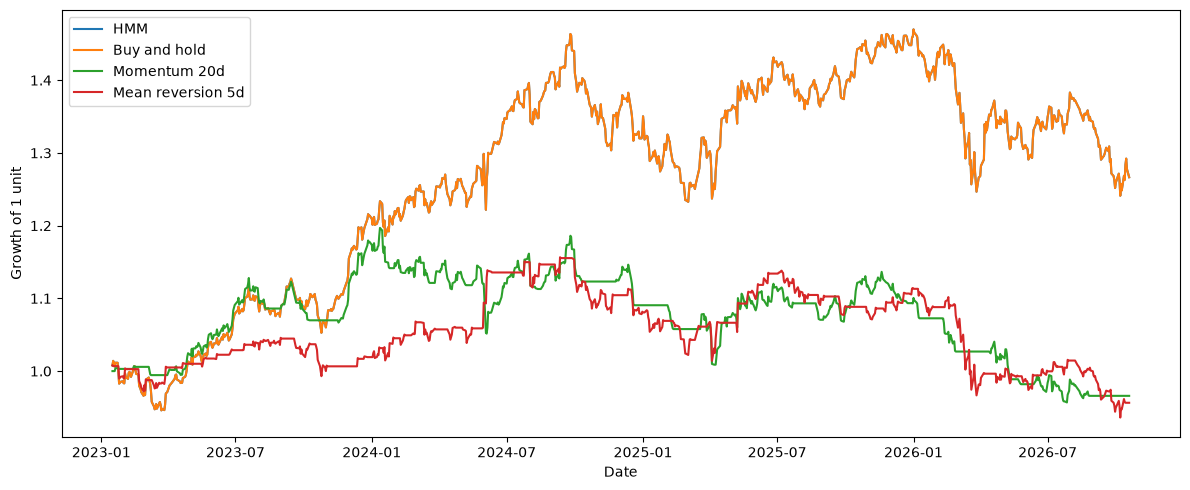

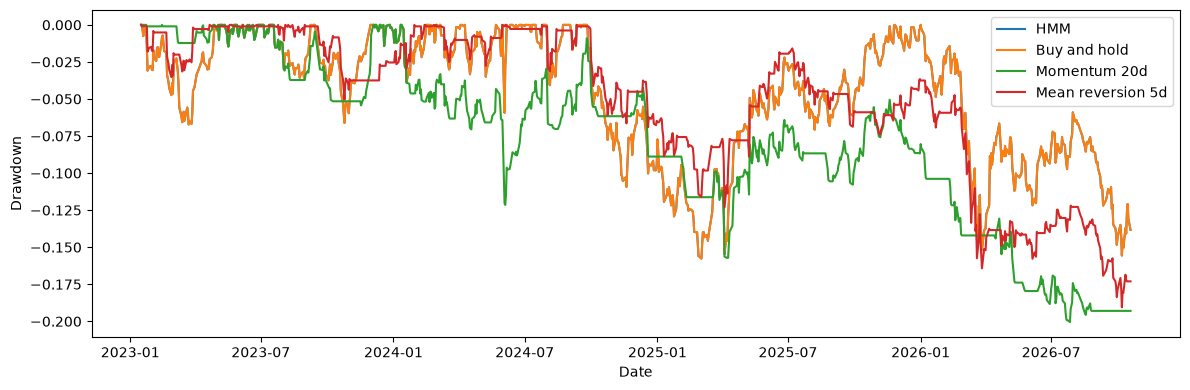

In [6]:
plt.figure(figsize=(12, 5))
for name, curve in backtests.items():
    plt.plot(curve["date"], curve["equity"], label=name)

plt.xlabel("Date")
plt.ylabel("Growth of 1 unit")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 4))
for name, curve in backtests.items():
    plt.plot(curve["date"], curve["drawdown"], label=name)

plt.xlabel("Date")
plt.ylabel("Drawdown")
plt.legend()
plt.tight_layout()
plt.show()

## Save results

In [7]:
summary_df.to_csv("strategy_backtest_summary.csv", index_label="strategy")

for name, curve in backtests.items():
    safe_name = name.lower().replace(" ", "_")
    curve.to_csv(f"backtest_{safe_name}.csv", index=False)

test.to_csv("test_strategy_signals.csv", index_label="market_row")
print("Saved backtest summary, equity curves, and test signals.")

Saved backtest summary, equity curves, and test signals.
